# 01 · Data exploration

What the supplied data looks like and the findings that shaped the features in notebook 02.
Only `data/train.csv` and `data/test.csv` are used (no outside data).

In [1]:
import sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from src.utils import load_raw, auc, SENTINEL_DAYS

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
train, test = load_raw()
y = train.TARGET
print(f'train {train.shape}, test {test.shape}; default rate {y.mean():.2%} ({y.sum():,} defaults)')
print('IDs unique and disjoint:', train.SK_ID_CURR.is_unique and test.SK_ID_CURR.is_unique
      and not set(train.SK_ID_CURR) & set(test.SK_ID_CURR))
train.head(3)

train (171202, 34), test (61500, 33); default rate 8.07% (13,821 defaults)
IDs unique and disjoint: True


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


## 1. Missing values
Missingness is heavy for a few columns and is **not** random: e.g. applicants with missing credit-bureau
request counts default more often (compare the two rate columns). Rows are therefore never dropped and
missingness is kept as information.

In [2]:
missing = train.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
rate_if_missing = pd.Series({c: y[train[c].isna()].mean() for c in missing.index})
rate_if_present = pd.Series({c: y[train[c].notna()].mean() for c in missing.index})
pd.DataFrame({'missing share': missing, 'default rate if missing': rate_if_missing,
              'default rate if present': rate_if_present}).round(3)

,missing share,default rate if missing,default rate if present
EXT_SOURCE_1,0.695,0.083,0.075
OWN_CAR_AGE,0.660,0.085,0.073
EXT_SOURCE_3,0.319,0.089,0.077
AMT_REQ_CREDIT_BUREAU_MON,0.135,0.104,0.077
AMT_REQ_CREDIT_BUREAU_QRT,0.135,0.104,0.077
AMT_REQ_CREDIT_BUREAU_HOUR,0.135,0.104,0.077
AMT_REQ_CREDIT_BUREAU_YEAR,0.135,0.104,0.077
EXT_SOURCE_2,0.002,0.079,0.081
CNT_FAM_MEMBERS,0.000,0.000,0.081


## 2. A placeholder value
`DAYS_EMPLOYED = 365243` (about +1,000 years) appears for 18% of applicants, almost all pensioners. It is a code
for "not employed", so it becomes missing plus a flag.

In [3]:
sentinel = train.DAYS_EMPLOYED.eq(SENTINEL_DAYS)
print(f'sentinel share: {sentinel.mean():.1%}; default rate with sentinel {y[sentinel].mean():.3f} vs {y[~sentinel].mean():.3f}')
train.loc[sentinel, 'NAME_INCOME_TYPE'].value_counts().head(3)

sentinel share: 18.0%; default rate with sentinel 0.054 vs 0.087


NAME_INCOME_TYPE
Pensioner     30888
Unemployed       10
Name: count, dtype: int64

## 3. Which columns carry signal on their own?
AUC of each numeric column used alone as a score (0.5 = useless; shown as max(AUC, 1 − AUC)).
The three external credit scores dominate; everything else is weak individually, so most gains must come
from combinations and interactions.

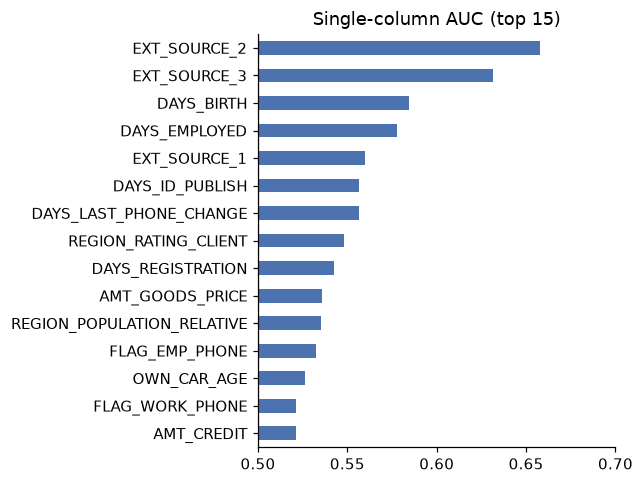

In [4]:
numeric = [c for c in train.select_dtypes('number').columns if c not in ('SK_ID_CURR', 'TARGET')]
single = {}
for c in numeric:
    x = train[c].replace(SENTINEL_DAYS, np.nan) if c == 'DAYS_EMPLOYED' else train[c]
    a = auc(y, x.fillna(x.median()))
    single[c] = max(a, 1 - a)
single = pd.Series(single).sort_values()
ax = single.tail(15).plot.barh(figsize=(6, 4.5), color='#4C72B0')
ax.axvline(0.5, color='grey', lw=.8)
ax.set_xlim(.5, .7)
ax.set_title('Single-column AUC (top 15)')
plt.tight_layout()

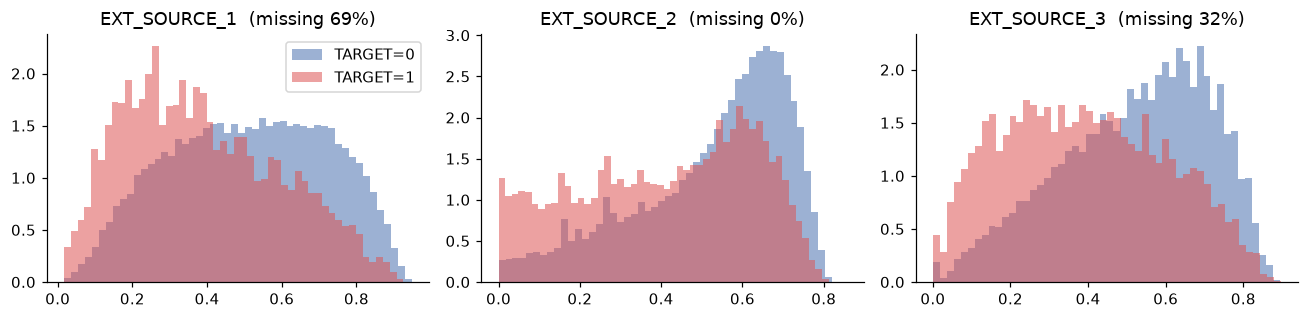

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, c in zip(axes, ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    for t, color in [(0, '#4C72B0'), (1, '#DD5555')]:
        ax.hist(train.loc[y == t, c].dropna(), bins=50, density=True, alpha=.55, color=color, label=f'TARGET={t}')
    ax.set_title(f'{c}  (missing {train[c].isna().mean():.0%})')
axes[0].legend()
plt.tight_layout()

## 4. Categorical columns
Default rates differ clearly between income types, education levels and occupations.

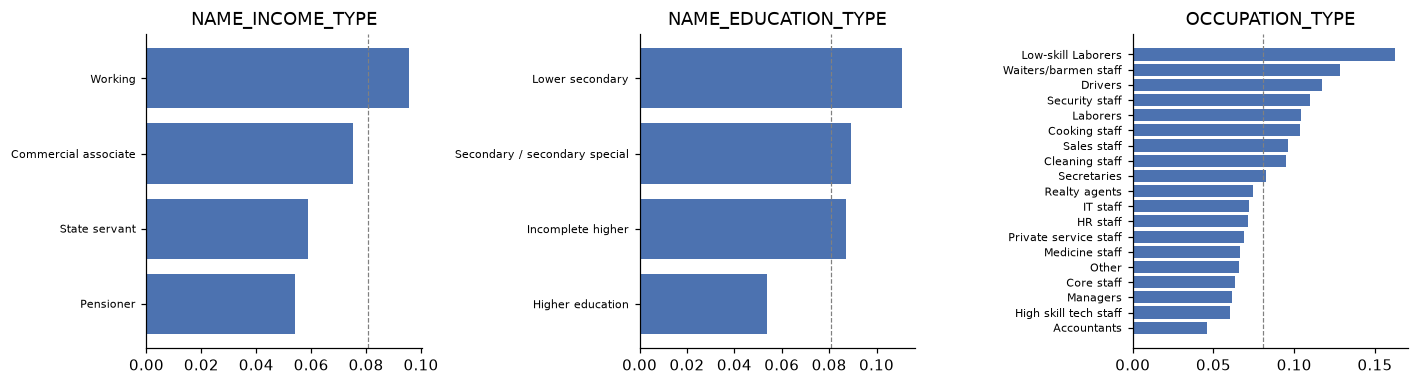

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ['NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE']):
    g = train.fillna({c: 'missing'}).groupby(c).TARGET.agg(['mean', 'size'])
    g = g[g['size'] >= 200].sort_values('mean')
    ax.barh(g.index, g['mean'], color='#4C72B0')
    ax.axvline(y.mean(), color='grey', ls='--', lw=.8)
    ax.set_title(c)
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout()

## 5. Loan term structure
`AMT_CREDIT / AMT_ANNUITY` would be the number of payments if loans carried no interest. Because the annuity
includes interest, the ratio sits *below* the true term, and the gap depends on the price of the loan.
The distribution is very spiky: a few standard (term, rate) products account for most loans.
Default rate jumps around strongly and non-monotonically with the ratio's position relative to 12-payment
blocks, which a model can use to tell products and price levels apart. This motivates the term/rate features
in notebook 02 (signed and absolute distance to the nearest multiple, rounded term, rate implied by an
assumed term). They improved validation AUC in the earlier rounds.

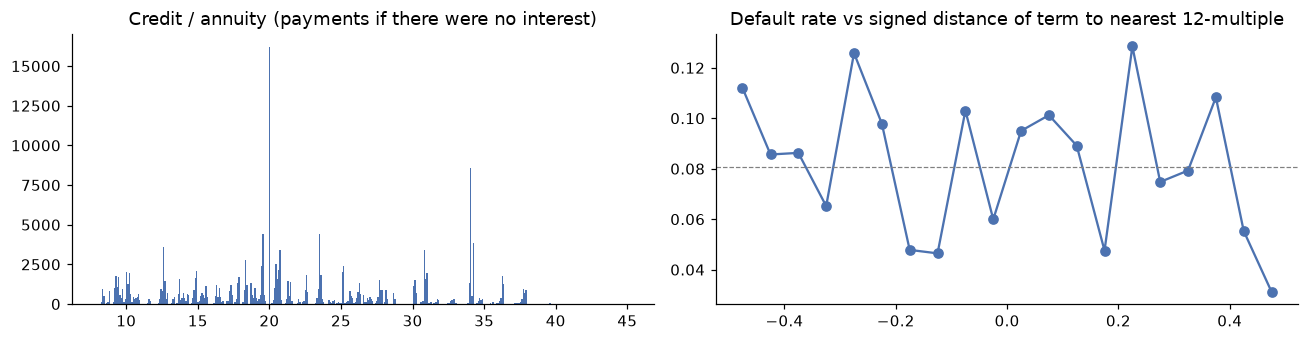

In [7]:
term = train.AMT_CREDIT / train.AMT_ANNUITY
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(term.clip(5, 45), bins=400, color='#4C72B0')
axes[0].set_title('Credit / annuity (payments if there were no interest)')
signed = term / 12 - np.rint(term / 12)
bins = pd.cut(signed, 20)
rate = y.groupby(bins, observed=True).mean()
axes[1].plot([b.mid for b in rate.index], rate.values, marker='o', color='#4C72B0')
axes[1].axhline(y.mean(), color='grey', ls='--', lw=.8)
axes[1].set_title('Default rate vs signed distance of term to nearest 12-multiple')
plt.tight_layout()

## 6. Are train and test alike? (adversarial validation)
A classifier trying to tell train rows from test rows. AUC near 0.5 means the two look alike, so random
cross-validation on train is a fair stand-in for the test set.

In [8]:
both = pd.concat([train.drop(columns='TARGET'), test]).drop(columns='SK_ID_CURR')
for c in both.select_dtypes(exclude='number').columns:
    both[c] = both[c].astype('category')
is_test = np.r_[np.zeros(len(train)), np.ones(len(test))]
p = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, verbosity=-1), both, is_test,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
print(f'train-vs-test AUC: {auc(is_test, p):.4f}')

train-vs-test AUC: 0.5127


## 7. Repeat applicants
The `DAYS_*` columns count back from the application date. If one person applies twice, `DAYS_BIRTH`,
`DAYS_ID_PUBLISH` and `DAYS_REGISTRATION` all shift by the same amount, so their **differences** stay fixed.
Rows sharing (gender, birth − ID publish, birth − registration) are probably the same person.
The key is not perfect (chance collisions exist), so it is used as a feature, never as a rule.

In [9]:
def applicant_key(df):
    return (df.CODE_GENDER.astype(str) + '|' + (df.DAYS_BIRTH - df.DAYS_ID_PUBLISH).astype(str) + '|'
            + (df.DAYS_BIRTH - df.DAYS_REGISTRATION).round().astype(str))

key = applicant_key(train)
size = key.map(key.value_counts())
groups = train.assign(key=key)[size > 1].groupby('key').TARGET.agg(['size', 'sum'])
# P(another application in the group defaulted | this one defaulted)
pairs_pos = (groups['sum'] * (groups['sum'] - 1)).sum() / (groups['sum'] * (groups['size'] - 1)).sum()
test_match = applicant_key(test).isin(set(key)).mean()
print(f'train rows in a multi-row group: {(size > 1).mean():.1%}; test rows matching a train group: {test_match:.1%}')
print(f'if one application defaulted, another in its group defaulted {pairs_pos:.1%} of the time (base rate {y.mean():.1%})')

train rows in a multi-row group: 3.2%; test rows matching a train group: 3.0%
if one application defaulted, another in its group defaulted 24.6% of the time (base rate 8.1%)
